# A14 — Separating Good from Ugly Recordings



## Problem statement

A recording is *ugly* when MoveNet cannot reliably estimate joint positions due to poor lighting, cluttered background, or confusing clothing.  
The goal is to **predict recording quality before the exercise starts**, using only the first few frames.  
If we can predict ugliness early, users can fix their recording environment before wasting a full session.

### Response
The **whole-recording confidence score**: the mean of all keypoint confidence values across every frame of the full recording.  
High confidence ≈ clean recording. Low confidence ≈ ugly recording.

### Predictors
The **first `c` frames** of the recording (before the exercise starts), using per-joint positions and per-joint confidence scores.  
Per frame: 13 joints × (x, y, score) = **39 features** → total input = `39 × c`.

### Deep Learning Steps
1. Load and prepare movement data  
2. Define Deep Learning network models (Dense, CNN-1D, LSTM)  
3. Compile DL models  
4. Cross-validation splits  
5. Train + hyperparameter search  
6. Evaluate predictions (MAE/MSE + practical threshold analysis)

### Imports, settings, paths

In [28]:
from pathlib import Path
import os
import random
import warnings
import json
import copy
import joblib
from contextlib import nullcontext

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import mlflow
import mlflow.pytorch
from mlflow.tracking import MlflowClient
from dotenv import load_dotenv
from os import getenv

warnings.filterwarnings("ignore")

# Reproducibility
RANDOM_SEED = 42
os.environ["PYTHONHASHSEED"] = str(RANDOM_SEED)
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")



FIRST_C = 10          
N_SPLITS = 10        
VALIDATION_SPLIT = 0.10

EPOCHS = 150
PATIENCE = 20
BATCH_SIZE = 16
LEARNING_RATE = 1e-3

UGLY_THRESHOLD = 0.5

NUM_WORKERS = 0
PIN_MEMORY = torch.cuda.is_available()

MOVENET_DIR = Path("../../../data/processed/movenet/csv_output")

output_dir   = Path("reporting/results")
artifact_dir = Path("reporting/artifacts")
output_dir.mkdir(parents=True, exist_ok=True)
artifact_dir.mkdir(parents=True, exist_ok=True)

print("DEVICE:", DEVICE)
print("MOVENET_DIR:", MOVENET_DIR)
print(f"Predictor window: first {FIRST_C} frames")
print(f"Ugly threshold: confidence < {UGLY_THRESHOLD}")

DEVICE: cpu
MOVENET_DIR: ../../../data/processed/movenet/csv_output
Predictor window: first 10 frames
Ugly threshold: confidence < 0.5


### MLflow setup

In [29]:
load_dotenv("../../../../../env")

tracking_uri = getenv("MLFLOW_TRACKING_URI")
print("MLFLOW_TRACKING_URI =", tracking_uri)

if tracking_uri:
    mlflow.set_tracking_uri(tracking_uri)
else:
    raise RuntimeError("MLFLOW_TRACKING_URI not set. Fix env path/variable.")

EXPERIMENT_NAME = "A14_ugly_recording_detection"
mlflow.set_experiment(EXPERIMENT_NAME)

print("MLflow tracking URI:", mlflow.get_tracking_uri())
print("MLflow experiment:", EXPERIMENT_NAME)

client = MlflowClient()

MLFLOW_TRACKING_URI = https://172.27.62.170:5001/
MLflow tracking URI: https://172.27.62.170:5001/
MLflow experiment: A14_ugly_recording_detection


### MoveNet loading helpers

Same 13-joint mapping as A13, keeping the project-wide convention.

In [30]:
MOVENET_TO_ASSIGNMENT = {
    "nose":           "head",
    "left_shoulder":  "left_shoulder",
    "left_elbow":     "left_elbow",
    "right_shoulder": "right_shoulder",
    "right_elbow":    "right_elbow",
    "left_wrist":     "left_hand",
    "right_wrist":    "right_hand",
    "left_hip":       "left_hip",
    "right_hip":      "right_hip",
    "left_knee":      "left_knee",
    "right_knee":     "right_knee",
    "left_ankle":     "left_foot",
    "right_ankle":    "right_foot",
}
JOINTS_13 = list(MOVENET_TO_ASSIGNMENT.values())
N_JOINTS = len(JOINTS_13)  # 13

# Feature columns per frame: x, y, score for each of the 13 joints
FEATURE_COLS_PER_FRAME = []
for joint in JOINTS_13:
    FEATURE_COLS_PER_FRAME.extend([f"{joint}_x", f"{joint}_y", f"{joint}_score"])
N_FEATURES = len(FEATURE_COLS_PER_FRAME)  # 39

FRAME_COL_CANDIDATES = ["frame_index", "frame", "frame_id", "FrameNo", "frame_no", "image_id"]

# All 17 MoveNet keypoint score columns — used to compute per-frame pose score
# Eyes and ears excluded — nose represents the head; 13 scores match the joint convention
ALL_MOVENET_SCORE_COLS = [
    "nose_score",
    "left_shoulder_score", "right_shoulder_score",
    "left_elbow_score", "right_elbow_score",
    "left_wrist_score", "right_wrist_score",
    "left_hip_score", "right_hip_score",
    "left_knee_score", "right_knee_score",
    "left_ankle_score", "right_ankle_score",
]


def find_frame_col(df: pd.DataFrame) -> str:
    for col in FRAME_COL_CANDIDATES:
        if col in df.columns:
            return col
    raise ValueError(f"No frame column found. Candidates: {FRAME_COL_CANDIDATES}")


def load_movenet_csv(csv_path) -> pd.DataFrame:
    """
    Load a MoveNet CSV.
    Returns a DataFrame with the 13-joint assignment columns PLUS a 'pose_score'
    column: the mean of all 17 keypoint confidence scores per frame.
    """
    df = pd.read_csv(csv_path)
    df.columns = [str(c).strip() for c in df.columns]

    frame_col = find_frame_col(df)
    out = pd.DataFrame()
    out["frame_index"] = pd.to_numeric(df[frame_col], errors="coerce").astype(int)

    # Per-frame pose score = mean of all 17 keypoint scores in that frame
    sc_cols_present = [c for c in ALL_MOVENET_SCORE_COLS if c in df.columns]
    out["pose_score"] = df[sc_cols_present].mean(axis=1)

    for movenet_joint, assignment_joint in MOVENET_TO_ASSIGNMENT.items():
        for suffix in ["x", "y", "score"]:
            src = f"{movenet_joint}_{suffix}"
            dst = f"{assignment_joint}_{suffix}"
            out[dst] = pd.to_numeric(df[src], errors="coerce")

    out = out.sort_values("frame_index").reset_index(drop=True)
    out = out.fillna(0.0)
    return out


print(f"13 joints configured. Features per frame: {N_FEATURES}")
print(f"Total input features (first {FIRST_C} frames): {N_FEATURES} × {FIRST_C} = {N_FEATURES * FIRST_C}")
print(f"Per-frame pose score: mean of {len(ALL_MOVENET_SCORE_COLS)} keypoint scores")

13 joints configured. Features per frame: 39
Total input features (first 10 frames): 39 × 10 = 390
Per-frame pose score: mean of 13 keypoint scores


---
## Step 1 — Load and prepare movement data

**Predictors X**: First `c = 10` frames, features = x/y/score per joint (39 × 10 = 390 values per recording).

**Response y**: Whole-recording confidence score = mean of the per-frame pose scores across all frames.  
Per-frame pose score = mean of all 17 MoveNet keypoint confidence scores in that frame.

Since no manual "ugly/good" labels exist in this dataset, the regression target is the continuous confidence score.  
For the threshold analysis, recordings below the **30th percentile** of confidence are treated as "ugly".

In [31]:
def compute_recording_confidence(df: pd.DataFrame) -> float:
    """
    Whole-recording confidence score.
    = mean of per-frame pose scores across all frames
    where per-frame pose score = mean of all 17 keypoint confidence scores.
    """
    return float(df["pose_score"].mean())


def extract_first_c_features(df: pd.DataFrame, c: int) -> np.ndarray:
    """Take the first c frames and flatten to a 1-D feature vector."""
    subset = df.iloc[:c][FEATURE_COLS_PER_FRAME].values  # (c, 39)
    return subset.flatten()                               # (c*39,)


def load_dataset(movenet_dir: Path, c: int) -> pd.DataFrame:
    """Load all recordings, compute y (whole-recording confidence), extract first-c features."""
    if not movenet_dir.exists():
        raise FileNotFoundError(movenet_dir)

    rows = []
    for csv_path in sorted(movenet_dir.glob("*.csv")):
        sid = csv_path.stem
        df  = load_movenet_csv(csv_path)

        if len(df) < c:
            print(f"  Skipped {sid}: only {len(df)} frames (need {c})")
            continue

        y_conf = compute_recording_confidence(df)
        x_flat = extract_first_c_features(df, c)

        rows.append({
            "sequence_id": sid,
            "y_conf":      y_conf,
            "n_frames":    len(df),
            "x_flat":      x_flat,
        })

    catalog = pd.DataFrame(rows)
    print(f"Loaded {len(catalog)} recordings  "
          f"(conf range: [{catalog['y_conf'].min():.4f}, {catalog['y_conf'].max():.4f}])")
    return catalog


catalog_df = load_dataset(MOVENET_DIR, c=FIRST_C)
catalog_df.head(5)

Loaded 180 recordings  (conf range: [0.4424, 0.6240])


,sequence_id,y_conf,n_frames,x_flat
0,A1,0.589341,229,"[993.07, 254.03, 0.5925, 1056.36, 359.17, 0.63..."
1,A10,0.613089,257,"[998.6, 265.1, 0.6132, 1075.23, 366.02, 0.6426..."
2,A100,0.513539,223,"[979.72, 295.71, 0.3792, 1040.93, 353.39, 0.53..."
3,A101,0.508559,272,"[978.0, 291.88, 0.3455, 1060.79, 337.88, 0.659..."
4,A102,0.498808,212,"[999.09, 287.36, 0.4501, 1088.86, 344.09, 0.54..."


Full-recording confidence score statistics:
count    180.0000
mean       0.5500
std        0.0456
min        0.4424
25%        0.5085
50%        0.5587
75%        0.5898
max        0.6240
Name: y_conf, dtype: float64

Ugly threshold: 0.5
  Recordings below threshold (ugly): 35
  Recordings above threshold (good): 145


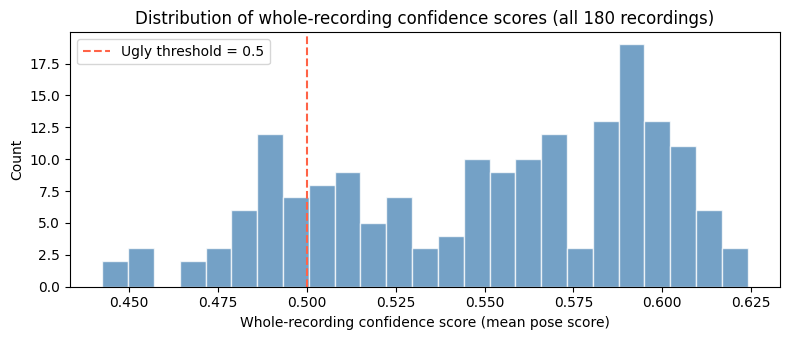

In [32]:
# ── Confidence score distribution 
print("Full-recording confidence score statistics:")
print(catalog_df["y_conf"].describe().round(4))

ugly_threshold = UGLY_THRESHOLD
print(f"\nUgly threshold: {ugly_threshold}")
print(f"  Recordings below threshold (ugly): {(catalog_df['y_conf'] < ugly_threshold).sum()}")
print(f"  Recordings above threshold (good): {(catalog_df['y_conf'] >= ugly_threshold).sum()}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(catalog_df["y_conf"], bins=25, color="steelblue", alpha=0.75, edgecolor="white")
ax.axvline(ugly_threshold, color="tomato", linestyle="--", lw=1.5,
           label=f"Ugly threshold = {ugly_threshold}")
ax.set_xlabel("Whole-recording confidence score (mean pose score)")
ax.set_ylabel("Count")
ax.set_title("Distribution of whole-recording confidence scores (all 180 recordings)")
ax.legend()
plt.tight_layout()
plt.savefig(output_dir / "a14_confidence_distribution.png", dpi=120)
plt.show()

In [33]:
#  Build X and y arrays 
X_raw        = np.stack(catalog_df["x_flat"].values)    # (N, 390)
y_raw        = catalog_df["y_conf"].values               # (N,)
sequence_ids = catalog_df["sequence_id"].values          # (N,)

is_ugly = (y_raw < ugly_threshold)

print(f"X_raw shape : {X_raw.shape}")
print(f"y_raw range : [{y_raw.min():.4f}, {y_raw.max():.4f}]")
print(f"Ugly (conf < {UGLY_THRESHOLD}) : {is_ugly.sum()} recordings")
print(f"Good (conf >= {UGLY_THRESHOLD}) : {(~is_ugly).sum()} recordings")


#  Normalize y to [0, 1] so MSE gradients are well-conditioned 
y_scaler_global = MinMaxScaler()
y_scaled = y_scaler_global.fit_transform(y_raw.reshape(-1, 1)).flatten()
print(f"\ny_scaled range: [{y_scaled.min():.4f}, {y_scaled.max():.4f}]")

X_raw shape : (180, 390)
y_raw range : [0.4424, 0.6240]
Ugly (conf < 0.5) : 35 recordings
Good (conf >= 0.5) : 145 recordings

y_scaled range: [0.0000, 1.0000]


---
## Step 2 — Define Deep Learning network models

Three architectures tested, all as **regressors** (predict continuous confidence score).
Parameter budgets are kept small to ensure online decision capability (client-side).

| Architecture | Input shape | Notes |
|---|---|---|
| **Dense** | `(batch, c*39)` | Flat fully-connected |
| **CNN-1D** | `(batch, 39, c)` | 1-D conv over time axis |
| **LSTM** | `(batch, c, 39)` | Recurrent, time-first |

In [34]:
#  Dense regressor 
class DenseRegressor(nn.Module):
    """
    Fully-connected regressor.  Input: flat (c * 39) vector.
    Hidden layers use ReLU + optional Dropout.
    Output: scalar confidence score.
    """
    def __init__(
        self,
        in_dim: int,
        hidden_dims: tuple = (32,),
        dropout: float = 0.20,
    ):
        super().__init__()
        layers = []
        prev = in_dim
        for h in hidden_dims:
            layers += [nn.Linear(prev, h), nn.ReLU()]
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(-1)


#  CNN-1D regressor 
class CNN1DRegressor(nn.Module):
    """
    1-D convolutional regressor.  Input: (batch, n_features, seq_len).
    Conv layers extract local temporal patterns; AdaptiveAvgPool collapses time.
    """
    def __init__(
        self,
        n_features: int,
        seq_len: int,
        conv_channels: tuple = (16,),
        kernel_size: int = 3,
        dense_dims: tuple = (),
        dropout: float = 0.20,
    ):
        super().__init__()
        conv_layers = []
        in_ch = n_features
        for out_ch in conv_channels:
            padding = kernel_size // 2
            conv_layers += [
                nn.Conv1d(in_ch, out_ch, kernel_size=kernel_size, padding=padding),
                nn.BatchNorm1d(out_ch),
                nn.ReLU(),
            ]
            if dropout > 0:
                conv_layers.append(nn.Dropout(dropout))
            in_ch = out_ch

        self.cnn  = nn.Sequential(*conv_layers)
        self.pool = nn.AdaptiveAvgPool1d(1)

        dense_layers = []
        prev = in_ch
        for h in dense_dims:
            dense_layers += [nn.Linear(prev, h), nn.ReLU()]
            if dropout > 0:
                dense_layers.append(nn.Dropout(dropout))
            prev = h
        dense_layers.append(nn.Linear(prev, 1))
        self.head = nn.Sequential(*dense_layers)

    def forward(self, x):
        # x: (batch, n_features, seq_len)
        x = self.cnn(x)
        x = self.pool(x).squeeze(-1)
        return self.head(x).squeeze(-1)


#  LSTM regressor 
class LSTMRegressor(nn.Module):
    """
    LSTM regressor.  Input: (batch, seq_len, n_features) — time-first.
    Uses the last hidden state as the sequence representation.
    """
    def __init__(
        self,
        n_features: int,
        hidden_size: int = 16,
        num_layers: int = 1,
        dense_dims: tuple = (),
        dropout: float = 0.20,
    ):
        super().__init__()
        lstm_dropout = dropout if num_layers > 1 else 0.0
        self.lstm = nn.LSTM(
            input_size=n_features,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=lstm_dropout,
        )
        self.post_dropout = nn.Dropout(dropout)

        layers = []
        prev = hidden_size
        for h in dense_dims:
            layers += [nn.Linear(prev, h), nn.ReLU()]
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.head = nn.Sequential(*layers)

    def forward(self, x):
        # x: (batch, seq_len, n_features)
        _, (h_n, _) = self.lstm(x)
        last_hidden = h_n[-1]                 # (batch, hidden_size)
        last_hidden = self.post_dropout(last_hidden)
        return self.head(last_hidden).squeeze(-1)


#  Parameter count utility 
def count_params(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


# Print representative param counts
in_dim = N_FEATURES * FIRST_C  # 390
print(f"{'Model':<40} {'Params':>8}")
print("-" * 50)
for name, m in [
    ("Dense [32]",           DenseRegressor(in_dim, (32,))),
    ("Dense [16, 8]",         DenseRegressor(in_dim, (16, 8))),
    ("Dense [8]",             DenseRegressor(in_dim, (8,))),
    ("CNN [8] k3",            CNN1DRegressor(N_FEATURES, FIRST_C, (8,),  3)),
    ("CNN [16] k3",           CNN1DRegressor(N_FEATURES, FIRST_C, (16,), 3)),
    ("CNN [8,16] k3",         CNN1DRegressor(N_FEATURES, FIRST_C, (8,16), 3)),
    ("LSTM h=8",              LSTMRegressor(N_FEATURES, 8)),
    ("LSTM h=16",             LSTMRegressor(N_FEATURES, 16)),
    ("LSTM h=8 + FC[8]",      LSTMRegressor(N_FEATURES, 8,  dense_dims=(8,))),
]:
    print(f"  {name:<38} {count_params(m):>8,}")

Model                                      Params
--------------------------------------------------
  Dense [32]                               12,545
  Dense [16, 8]                             6,401
  Dense [8]                                 3,137
  CNN [8] k3                                  969
  CNN [16] k3                               1,937
  CNN [8,16] k3                             1,409
  LSTM h=8                                  1,577
  LSTM h=16                                 3,665
  LSTM h=8 + FC[8]                          1,649


---
## Step 3 — Compile the DL model

- **Optimizer**: Adam (also test RMSprop for completeness)
- **Loss**: MSE (Mean Squared Error) — regression target
- **Metric**: MAE (Mean Absolute Error) — interpretable in confidence-score units

In [35]:
#  Dataset wrapper 
class SequenceDataset(Dataset):
    """Wraps X (array) and y (array) for DataLoader."""
    def __init__(self, X: np.ndarray, y: np.ndarray):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


def make_loader(X: np.ndarray, y: np.ndarray, batch_size: int, shuffle: bool) -> DataLoader:
    return DataLoader(
        SequenceDataset(X, y),
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY,
    )


# Training + evaluation helpers
def train_one_model(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    learning_rate: float,
    epochs: int,
    patience: int,
    optimizer_name: str = "adam",
) -> list[dict]:
    criterion = nn.MSELoss()
    if optimizer_name == "rmsprop":
        optimizer = torch.optim.RMSprop(model.parameters(), lr=learning_rate)
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    best_state      = copy.deepcopy(model.state_dict())
    best_val_loss   = np.inf
    patience_counter = 0
    history         = []

    for epoch in range(epochs):
        model.train()
        train_loss_sum, n_train = 0.0, 0

        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(X_batch), y_batch)
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * len(X_batch)
            n_train        += len(X_batch)

        # Validation
        model.eval()
        val_preds, val_true = [], []
        val_loss_sum, n_val = 0.0, 0
        with torch.no_grad():
            for X_b, y_b in val_loader:
                X_b, y_b = X_b.to(DEVICE), y_b.to(DEVICE)
                out = model(X_b)
                val_loss_sum += criterion(out, y_b).item() * len(X_b)
                n_val        += len(X_b)
                val_preds.extend(out.detach().cpu().numpy().tolist())
                val_true.extend(y_b.detach().cpu().numpy().tolist())

        val_mae = mean_absolute_error(val_true, val_preds)
        val_mse = val_loss_sum / max(n_val, 1)

        history.append({
            "epoch":      epoch + 1,
            "train_loss": train_loss_sum / max(n_train, 1),
            "val_loss":   val_mse,
            "val_mae":    val_mae,
        })

        if val_mse < best_val_loss:
            best_val_loss    = val_mse
            best_state       = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                break

    model.load_state_dict(best_state)
    return history


def predict_scores(model: nn.Module, X: np.ndarray) -> np.ndarray:
    model.eval()
    with torch.no_grad():
        t = torch.tensor(X, dtype=torch.float32).to(DEVICE)
        preds = model(t).detach().cpu().numpy()
    return np.clip(preds, 0.0, 1.0)


print("Training helpers defined (MSE loss, Adam/RMSprop, early stopping).")

Training helpers defined (MSE loss, Adam/RMSprop, early stopping).


---
## Step 4 — Cross-validation splits

- **10-fold GroupKFold** (each recording is its own group, no leakage within folds)
- MinMaxScaler is **fitted on the training fold only** and applied to the test fold

In [36]:
def prepare_fold_data(
    X_raw: np.ndarray,
    y_raw: np.ndarray,
    train_idx: np.ndarray,
    test_idx: np.ndarray,
    val_fraction: float = VALIDATION_SPLIT,
    random_state: int = RANDOM_SEED,
) -> dict:
    """
    Split a fold into train/val/test with per-fold normalisation.
    Scaler fitted on train, applied to val+test.
    """
    n_val = max(1, int(len(train_idx) * val_fraction))
    rng = np.random.default_rng(random_state)
    perm = rng.permutation(len(train_idx))
    val_local   = perm[:n_val]
    train_local = perm[n_val:]

    tr_idx  = train_idx[train_local]
    val_idx = train_idx[val_local]

    X_scaler = MinMaxScaler().fit(X_raw[tr_idx])
    y_scaler = MinMaxScaler().fit(y_raw[tr_idx].reshape(-1, 1))

    def scale_X(idx):
        return X_scaler.transform(X_raw[idx])

    def scale_y(idx):
        return y_scaler.transform(y_raw[idx].reshape(-1, 1)).flatten()

    return {
        "X_tr":    scale_X(tr_idx),  "y_tr":  scale_y(tr_idx),
        "X_val":   scale_X(val_idx), "y_val": scale_y(val_idx),
        "X_test":  scale_X(test_idx),"y_test":scale_y(test_idx),
        "tr_idx":  tr_idx, "val_idx": val_idx, "test_idx": test_idx,
        "X_scaler": X_scaler, "y_scaler": y_scaler,
    }


gkf = GroupKFold(n_splits=N_SPLITS)
fold_splits = list(gkf.split(X_raw, y_raw, groups=sequence_ids))

print(f"10-fold cross-validation splits ready ({N_SPLITS} folds).")
for fold_i, (tr, te) in enumerate(fold_splits[:3]):
    print(f"  Fold {fold_i}: train={len(tr)}, test={len(te)}")
print("  ...")

10-fold cross-validation splits ready (10 folds).
  Fold 0: train=162, test=18
  Fold 1: train=162, test=18
  Fold 2: train=162, test=18
  ...


---
## Step 5 — Train the DL model (hyperparameter search)

### Architecture input reshaping
- Dense: `X` stays as `(N, c*39)` — flat vector  
- CNN-1D: reshape to `(N, 39, c)` — features as channels, time as length  
- LSTM: reshape to `(N, c, 39)` — time-first

In [37]:
def reshape_for_arch(X: np.ndarray, arch: str) -> np.ndarray:
    """Reshape flat (N, c*39) array for the target architecture."""
    N = len(X)
    if arch == "dense":
        return X                                           # (N, c*39)
    elif arch == "cnn":
        return X.reshape(N, FIRST_C, N_FEATURES).transpose(0, 2, 1)  # (N, 39, c)
    elif arch == "lstm":
        return X.reshape(N, FIRST_C, N_FEATURES)          # (N, c, 39)
    raise ValueError(arch)


def build_model(config: dict) -> nn.Module:
    arch = config["arch"]
    if arch == "dense":
        return DenseRegressor(
            in_dim=N_FEATURES * FIRST_C,
            hidden_dims=config["hidden_dims"],
            dropout=config["dropout"],
        ).to(DEVICE)
    elif arch == "cnn":
        return CNN1DRegressor(
            n_features=N_FEATURES,
            seq_len=FIRST_C,
            conv_channels=config["conv_channels"],
            kernel_size=config.get("kernel_size", 3),
            dense_dims=config.get("dense_dims", ()),
            dropout=config["dropout"],
        ).to(DEVICE)
    elif arch == "lstm":
        return LSTMRegressor(
            n_features=N_FEATURES,
            hidden_size=config["hidden_size"],
            num_layers=config.get("num_layers", 1),
            dense_dims=config.get("dense_dims", ()),
            dropout=config["dropout"],
        ).to(DEVICE)
    raise ValueError(arch)


print("Architecture reshaping helpers ready.")

Architecture reshaping helpers ready.


In [38]:
# Hyperparameter search  
# Objective: minimise parameters while keeping
# validation MAE low.

SEARCH_CONFIGS = [
    #  Dense 
    {"name": "dense_32_drop020",     "arch": "dense", "hidden_dims": (32,),    "dropout": 0.20, "lr": 1e-3, "batch": 16},
    {"name": "dense_16_8_drop020",   "arch": "dense", "hidden_dims": (16, 8),  "dropout": 0.20, "lr": 1e-3, "batch": 16},
    {"name": "dense_16_8_drop010",   "arch": "dense", "hidden_dims": (16, 8),  "dropout": 0.10, "lr": 1e-3, "batch": 16},
    {"name": "dense_8_drop010",      "arch": "dense", "hidden_dims": (8,),     "dropout": 0.10, "lr": 1e-3, "batch": 16},
    {"name": "dense_8_drop020_lr5e4","arch": "dense", "hidden_dims": (8,),     "dropout": 0.20, "lr": 5e-4, "batch": 16},
    #  CNN-1D 
    {"name": "cnn_8_k3_drop020",         "arch": "cnn", "conv_channels": (8,),    "kernel_size": 3, "dense_dims": (),   "dropout": 0.20, "lr": 1e-3, "batch": 16},
    {"name": "cnn_16_k3_drop020",        "arch": "cnn", "conv_channels": (16,),   "kernel_size": 3, "dense_dims": (),   "dropout": 0.20, "lr": 1e-3, "batch": 16},
    {"name": "cnn_8_k3_fc8_drop020",     "arch": "cnn", "conv_channels": (8,),    "kernel_size": 3, "dense_dims": (8,), "dropout": 0.20, "lr": 1e-3, "batch": 16},
    {"name": "cnn_8_16_k3_drop010",      "arch": "cnn", "conv_channels": (8,16),  "kernel_size": 3, "dense_dims": (),   "dropout": 0.10, "lr": 1e-3, "batch": 16},
    #  LSTM 
    {"name": "lstm_h8_drop020",       "arch": "lstm", "hidden_size": 8,  "num_layers": 1, "dense_dims": (),   "dropout": 0.20, "lr": 1e-3, "batch": 16},
    {"name": "lstm_h16_drop020",      "arch": "lstm", "hidden_size": 16, "num_layers": 1, "dense_dims": (),   "dropout": 0.20, "lr": 1e-3, "batch": 16},
    {"name": "lstm_h8_fc8_drop020",   "arch": "lstm", "hidden_size": 8,  "num_layers": 1, "dense_dims": (8,), "dropout": 0.20, "lr": 1e-3, "batch": 16},
    {"name": "lstm_h8_drop010_lr5e4", "arch": "lstm", "hidden_size": 8,  "num_layers": 1, "dense_dims": (),   "dropout": 0.10, "lr": 5e-4, "batch": 16},
]

# Print parameter counts
print(f"{'Config':<32} {'Arch':<6} {'Params':>8}")
print("-" * 50)
for cfg in SEARCH_CONFIGS:
    m = build_model(cfg)
    print(f"  {cfg['name']:<30} {cfg['arch']:<6} {count_params(m):>8,}")

Config                           Arch     Params
--------------------------------------------------
  dense_32_drop020               dense    12,545
  dense_16_8_drop020             dense     6,401
  dense_16_8_drop010             dense     6,401
  dense_8_drop010                dense     3,137
  dense_8_drop020_lr5e4          dense     3,137
  cnn_8_k3_drop020               cnn         969
  cnn_16_k3_drop020              cnn       1,937
  cnn_8_k3_fc8_drop020           cnn       1,041
  cnn_8_16_k3_drop010            cnn       1,409
  lstm_h8_drop020                lstm      1,577
  lstm_h16_drop020               lstm      3,665
  lstm_h8_fc8_drop020            lstm      1,649
  lstm_h8_drop010_lr5e4          lstm      1,577


In [39]:
#  Run hyperparameter search (10-fold CV)
all_search_results = []

for cfg in SEARCH_CONFIGS:
    fold_maes, fold_mses = [], []

    for fold_i, (tr_idx, te_idx) in enumerate(fold_splits):
        fold = prepare_fold_data(X_raw, y_raw, tr_idx, te_idx)

        X_tr_r   = reshape_for_arch(fold["X_tr"],   cfg["arch"])
        X_val_r  = reshape_for_arch(fold["X_val"],  cfg["arch"])
        X_test_r = reshape_for_arch(fold["X_test"], cfg["arch"])

        train_loader = make_loader(X_tr_r,  fold["y_tr"],  cfg["batch"], shuffle=True)
        val_loader   = make_loader(X_val_r, fold["y_val"], cfg["batch"], shuffle=False)

        model = build_model(cfg)
        train_one_model(
            model, train_loader, val_loader,
            learning_rate=cfg["lr"],
            epochs=EPOCHS,
            patience=PATIENCE,
        )

        y_pred_s = predict_scores(model, X_test_r)
        y_test_s = fold["y_test"]

        # Inverse transform for MAE in original confidence-score units
        y_pred_orig = fold["y_scaler"].inverse_transform(y_pred_s.reshape(-1, 1)).flatten()
        y_test_orig = fold["y_scaler"].inverse_transform(y_test_s.reshape(-1, 1)).flatten()

        fold_mae = mean_absolute_error(y_test_orig, y_pred_orig)
        fold_mse = mean_squared_error( y_test_orig, y_pred_orig)
        fold_maes.append(fold_mae)
        fold_mses.append(fold_mse)

    mean_mae = np.mean(fold_maes)
    std_mae  = np.std(fold_maes)
    mean_mse = np.mean(fold_mses)

    m = build_model(cfg)
    all_search_results.append({
        "name":      cfg["name"],
        "arch":      cfg["arch"],
        "params":    count_params(m),
        "mean_mae":  round(mean_mae, 5),
        "std_mae":   round(std_mae, 5),
        "mean_mse":  round(mean_mse, 6),
    })
    print(f"  {cfg['name']:<32}  MAE={mean_mae:.5f} ± {std_mae:.5f}")

print("\nHyperparameter search complete.")

  dense_32_drop020                  MAE=0.01423 ± 0.00206
  dense_16_8_drop020                MAE=0.01577 ± 0.00374
  dense_16_8_drop010                MAE=0.01461 ± 0.00215
  dense_8_drop010                   MAE=0.01644 ± 0.00902
  dense_8_drop020_lr5e4             MAE=0.01571 ± 0.00351
  cnn_8_k3_drop020                  MAE=0.01631 ± 0.00372
  cnn_16_k3_drop020                 MAE=0.01490 ± 0.00231
  cnn_8_k3_fc8_drop020              MAE=0.01523 ± 0.00208
  cnn_8_16_k3_drop010               MAE=0.01569 ± 0.00295
  lstm_h8_drop020                   MAE=0.01523 ± 0.00225
  lstm_h16_drop020                  MAE=0.01398 ± 0.00226
  lstm_h8_fc8_drop020               MAE=0.01463 ± 0.00283
  lstm_h8_drop010_lr5e4             MAE=0.01474 ± 0.00266

Hyperparameter search complete.


---
## Step 6 — Evaluate DL model predictions

### 6a. Compare all configurations

=== Hyperparameter search summary (sorted by mean MAE) ===


,name,arch,params,mean_mae,std_mae,mean_mse
0,lstm_h16_drop020,lstm,3665,0.01398,0.00226,0.000336
1,dense_32_drop020,dense,12545,0.01423,0.00206,0.000336
2,dense_16_8_drop010,dense,6401,0.01461,0.00215,0.000356
3,lstm_h8_fc8_drop020,lstm,1649,0.01463,0.00283,0.000356
4,lstm_h8_drop010_lr5e4,lstm,1577,0.01474,0.00266,0.000376
5,cnn_16_k3_drop020,cnn,1937,0.01490,0.00231,0.000373
6,cnn_8_k3_fc8_drop020,cnn,1041,0.01523,0.00208,0.000423
7,lstm_h8_drop020,lstm,1577,0.01523,0.00225,0.000406
8,cnn_8_16_k3_drop010,cnn,1409,0.01569,0.00295,0.000425
9,dense_8_drop020_lr5e4,dense,3137,0.01571,0.00351,0.000414


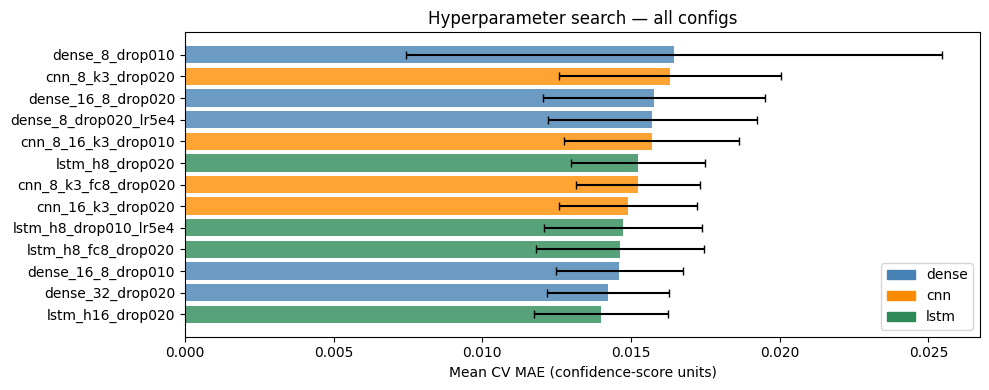

In [40]:
search_df = pd.DataFrame(all_search_results).sort_values("mean_mae")
search_df.to_csv(output_dir / "a14_hyperparameter_search_summary.csv", index=False)

print("=== Hyperparameter search summary (sorted by mean MAE) ===")
display(search_df.reset_index(drop=True))

fig, ax = plt.subplots(figsize=(10, 4))
colors = {"dense": "steelblue", "cnn": "darkorange", "lstm": "seagreen"}
bar_colors = [colors[row["arch"]] for _, row in search_df.iterrows()]
ax.barh(search_df["name"], search_df["mean_mae"], xerr=search_df["std_mae"],
        color=bar_colors, alpha=0.80, capsize=3)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=l) for l, c in colors.items()])
ax.set_xlabel("Mean CV MAE (confidence-score units)")
ax.set_title("Hyperparameter search — all configs")
plt.tight_layout()
plt.savefig(output_dir / "a14_hyperparameter_search_bar.png", dpi=120)
plt.show()

### 6b. Select champion configuration

In [41]:
best_name    = search_df.iloc[0]["name"]
CHAMPION_CFG = next(c for c in SEARCH_CONFIGS if c["name"] == best_name)

print("Champion config:", CHAMPION_CFG["name"])
print(json.dumps({k: str(v) for k, v in CHAMPION_CFG.items()}, indent=2))

Champion config: lstm_h16_drop020
{
  "name": "lstm_h16_drop020",
  "arch": "lstm",
  "hidden_size": "16",
  "num_layers": "1",
  "dense_dims": "()",
  "dropout": "0.2",
  "lr": "0.001",
  "batch": "16"
}


### 6c. Retrain champion on all data — final evaluation

In [42]:
# Final champion CV, collect per-fold predictions for aggregate evaluation
all_y_true, all_y_pred, all_seq_ids = [], [], []
champion_histories = []

for fold_i, (tr_idx, te_idx) in enumerate(fold_splits):
    fold = prepare_fold_data(X_raw, y_raw, tr_idx, te_idx)

    X_tr_r   = reshape_for_arch(fold["X_tr"],   CHAMPION_CFG["arch"])
    X_val_r  = reshape_for_arch(fold["X_val"],  CHAMPION_CFG["arch"])
    X_test_r = reshape_for_arch(fold["X_test"], CHAMPION_CFG["arch"])

    train_loader = make_loader(X_tr_r,  fold["y_tr"],  CHAMPION_CFG["batch"], shuffle=True)
    val_loader   = make_loader(X_val_r, fold["y_val"], CHAMPION_CFG["batch"], shuffle=False)

    model = build_model(CHAMPION_CFG)
    hist  = train_one_model(
        model, train_loader, val_loader,
        learning_rate=CHAMPION_CFG["lr"],
        epochs=EPOCHS, patience=PATIENCE,
    )
    champion_histories.extend([{"fold": fold_i, **h} for h in hist])

    y_pred_s = predict_scores(model, X_test_r)
    y_pred_o = fold["y_scaler"].inverse_transform(y_pred_s.reshape(-1,1)).flatten()
    y_test_o = fold["y_scaler"].inverse_transform(fold["y_test"].reshape(-1,1)).flatten()

    all_y_true.extend(y_test_o.tolist())
    all_y_pred.extend(y_pred_o.tolist())
    all_seq_ids.extend(sequence_ids[te_idx].tolist())

all_y_true = np.array(all_y_true)
all_y_pred = np.array(all_y_pred)

cv_mae = mean_absolute_error(all_y_true, all_y_pred)
cv_mse = mean_squared_error(all_y_true, all_y_pred)
cv_rmse = np.sqrt(cv_mse)

print(f"Champion CV results:")
print(f"  MAE  = {cv_mae:.5f}")
print(f"  MSE  = {cv_mse:.6f}")
print(f"  RMSE = {cv_rmse:.5f}")

pd.DataFrame(champion_histories).to_csv(
    output_dir / f"a14_champion_{CHAMPION_CFG['name']}_history.csv", index=False)

Champion CV results:
  MAE  = 0.01450
  MSE  = 0.000353
  RMSE = 0.01880


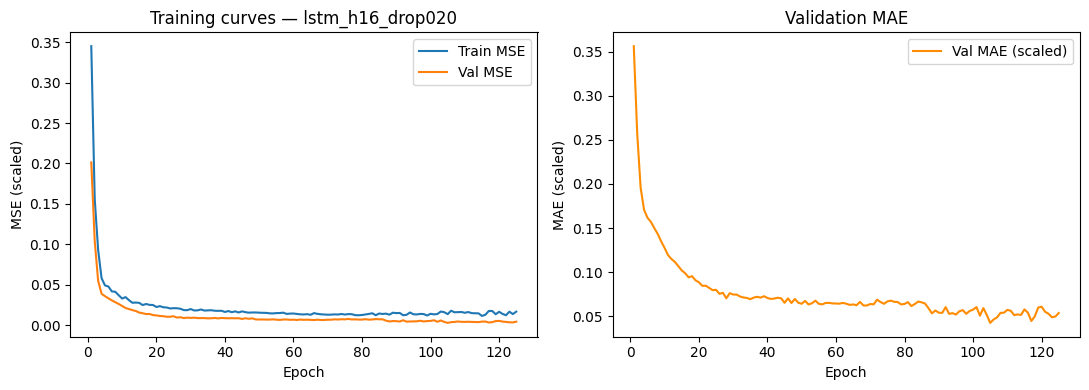

In [43]:
#  Training curves (mean over folds) 
hist_df   = pd.DataFrame(champion_histories)
mean_hist = hist_df.groupby("epoch")[["train_loss", "val_loss", "val_mae"]].mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(mean_hist["epoch"], mean_hist["train_loss"], label="Train MSE")
axes[0].plot(mean_hist["epoch"], mean_hist["val_loss"],   label="Val MSE")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE (scaled)")
axes[0].set_title(f"Training curves — {CHAMPION_CFG['name']}")
axes[0].legend()

axes[1].plot(mean_hist["epoch"], mean_hist["val_mae"], label="Val MAE (scaled)", color="darkorange")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("MAE (scaled)")
axes[1].set_title("Validation MAE")
axes[1].legend()

plt.tight_layout()
plt.savefig(output_dir / f"a14_champion_training_curves.png", dpi=120)
plt.show()

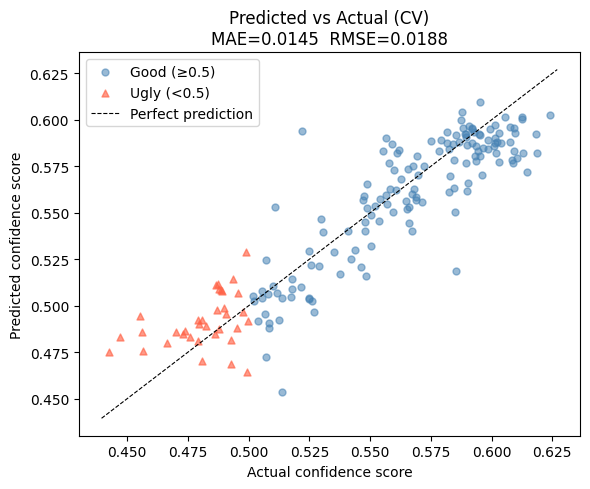

In [44]:
#  Scatter: predicted vs actual confidence score 
# Colour by whether the recording is "ugly" (confidence < UGLY_THRESHOLD)
fold_is_ugly = []
for _, te_idx in fold_splits:
    fold_is_ugly.extend(is_ugly[te_idx].tolist())
fold_is_ugly = np.array(fold_is_ugly)

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(all_y_true[~fold_is_ugly], all_y_pred[~fold_is_ugly],
           alpha=0.55, label=f"Good (≥{UGLY_THRESHOLD})", color="steelblue", s=25)
ax.scatter(all_y_true[fold_is_ugly], all_y_pred[fold_is_ugly],
           alpha=0.65, label=f"Ugly (<{UGLY_THRESHOLD})", color="tomato", s=25, marker="^")
lims = [min(all_y_true.min(), all_y_pred.min()) - 0.003,
        max(all_y_true.max(), all_y_pred.max()) + 0.003]
ax.plot(lims, lims, "k--", lw=0.8, label="Perfect prediction")
ax.set_xlabel("Actual confidence score")
ax.set_ylabel("Predicted confidence score")
ax.set_title(f"Predicted vs Actual (CV)\nMAE={cv_mae:.4f}  RMSE={cv_rmse:.4f}")
ax.legend()
plt.tight_layout()
plt.savefig(output_dir / "a14_predicted_vs_actual.png", dpi=120)
plt.show()

### 6d. Threshold analysis — practical usefulness in the application context

A **rejection threshold** τ is applied to the predicted confidence score.
If `predicted_confidence < τ`, the recording is rejected and the user is asked to improve their setup.
The threshold is set manually (`UGLY_THRESHOLD`). The plot above shows where it sits relative to the
full TPR/FPR curve so the trade-off can be assessed.

Trade-off:
- **τ too low**: ugly recordings pass through → errors downstream
- **τ too high**: good recordings are falsely rejected → poor user experience

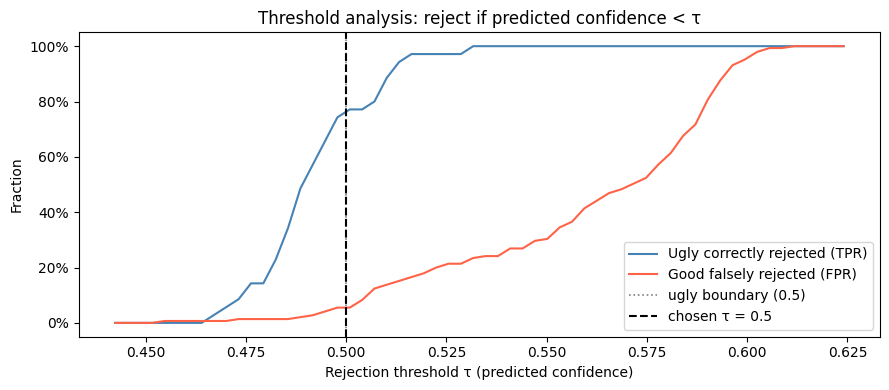

Chosen threshold τ = 0.5
  Ugly recordings correctly rejected : 77.1%
  Good recordings falsely rejected   : 5.5%


In [45]:
thresholds = np.linspace(all_y_true.min(), all_y_true.max(), 60)

# "Ugly" ground truth = recordings below UGLY_THRESHOLD
ugly_true = all_y_true < ugly_threshold


def threshold_stats(y_pred, ugly_true_mask, tau):
    """Return TPR and FPR for rejection at threshold tau."""
    rejected  = y_pred < tau
    good_mask = ~ugly_true_mask
    tpr = rejected[ugly_true_mask].mean() if ugly_true_mask.sum() > 0 else 0.0
    fpr = rejected[good_mask].mean()  if good_mask.sum()  > 0 else 0.0
    return tpr, fpr


tpr_list, fpr_list = [], []
for tau in thresholds:
    tpr, fpr = threshold_stats(all_y_pred, ugly_true, tau)
    tpr_list.append(tpr)
    fpr_list.append(fpr)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(thresholds, tpr_list, label="Ugly correctly rejected (TPR)", color="steelblue")
ax.plot(thresholds, fpr_list, label="Good falsely rejected (FPR)",   color="tomato")
ax.axvline(ugly_threshold, color="grey",
           linestyle=":", lw=1.2, label=f"ugly boundary ({ugly_threshold})")
ax.axvline(UGLY_THRESHOLD, color="black",
           linestyle="--", lw=1.5, label=f"chosen τ = {UGLY_THRESHOLD}")
ax.set_xlabel("Rejection threshold τ (predicted confidence)")
ax.set_ylabel("Fraction")
ax.set_title("Threshold analysis: reject if predicted confidence < τ")
ax.legend()
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
plt.tight_layout()
plt.savefig(output_dir / "a14_threshold_analysis.png", dpi=120)
plt.show()

# Stats at the chosen rejection threshold
tpr_at, fpr_at = threshold_stats(all_y_pred, ugly_true, UGLY_THRESHOLD)
print(f"Chosen threshold τ = {UGLY_THRESHOLD}")
print(f"  Ugly recordings correctly rejected : {tpr_at*100:.1f}%")
print(f"  Good recordings falsely rejected   : {fpr_at*100:.1f}%")

### 6e. Practical usefulness discussion

| Scenario | Effect |
|---|---|
| **τ too low** (lenient) | More ugly recordings pass through, downstream exercise scoring / start-stop detection will be less reliable because joint positions are noisy |
| **τ too high** (strict) | More good recordings are falsely rejected, users are frustrated when they are told to move/improve their setup even though it was fine |

In [46]:
#  Practical examples: τ too low / chosen / too high
tau_low  = UGLY_THRESHOLD - 0.010
tau_high = UGLY_THRESHOLD + 0.010

for tau_name, tau_val in [("too low", tau_low), ("chosen", UGLY_THRESHOLD), ("too high", tau_high)]:
    tpr, fpr = threshold_stats(all_y_pred, ugly_true, tau_val)
    rejected_pct = (all_y_pred < tau_val).mean() * 100
    print(f"\nτ = {tau_val:.4f}  ({tau_name})")
    print(f"  Total recordings rejected      : {rejected_pct:.1f}%")
    print(f"  Ugly correctly rejected (TPR)  : {tpr*100:.1f}%")
    print(f"  Good falsely rejected (FPR)    : {fpr*100:.1f}%")


τ = 0.4900  (too low)
  Total recordings rejected      : 11.7%
  Ugly correctly rejected (TPR)  : 51.4%
  Good falsely rejected (FPR)    : 2.1%

τ = 0.5000  (chosen)
  Total recordings rejected      : 19.4%
  Ugly correctly rejected (TPR)  : 77.1%
  Good falsely rejected (FPR)    : 5.5%

τ = 0.5100  (too high)
  Total recordings rejected      : 28.3%
  Ugly correctly rejected (TPR)  : 88.6%
  Good falsely rejected (FPR)    : 13.8%


### 6f. Train final model on all data and save

In [47]:
X_scaler_final = MinMaxScaler().fit(X_raw)
y_scaler_final = MinMaxScaler().fit(y_raw.reshape(-1, 1))

X_all_scaled = X_scaler_final.transform(X_raw)
y_all_scaled = y_scaler_final.transform(y_raw.reshape(-1, 1)).flatten()

X_all_r = reshape_for_arch(X_all_scaled, CHAMPION_CFG["arch"])

# Use 10% as a final validation set (no further hyperparameter search here)
n_val  = max(2, int(len(X_all_r) * VALIDATION_SPLIT))
rng    = np.random.default_rng(RANDOM_SEED)
perm   = rng.permutation(len(X_all_r))
tr_idx_final  = perm[n_val:]
val_idx_final = perm[:n_val]

final_train_loader = make_loader(X_all_r[tr_idx_final],  y_all_scaled[tr_idx_final],  CHAMPION_CFG["batch"], shuffle=True)
final_val_loader   = make_loader(X_all_r[val_idx_final], y_all_scaled[val_idx_final], CHAMPION_CFG["batch"], shuffle=False)

final_model = build_model(CHAMPION_CFG)
final_hist  = train_one_model(
    final_model, final_train_loader, final_val_loader,
    learning_rate=CHAMPION_CFG["lr"],
    epochs=EPOCHS, patience=PATIENCE,
)

print(f"Final model params: {count_params(final_model):,}")
print(f"Trained for {len(final_hist)} epochs")

#  Save artifacts 
model_path   = artifact_dir / "a14_final_champion_model.pt"
x_scaler_path = artifact_dir / "a14_final_champion_x_scaler.joblib"
y_scaler_path = artifact_dir / "a14_final_champion_y_scaler.joblib"
cfg_path     = artifact_dir / "a14_final_champion_config.json"

torch.save(final_model.state_dict(), model_path)
joblib.dump(X_scaler_final, x_scaler_path)
joblib.dump(y_scaler_final, y_scaler_path)

save_cfg = {k: str(v) if isinstance(v, tuple) else v for k, v in CHAMPION_CFG.items()}
save_cfg["first_c"] = FIRST_C
save_cfg["n_features"] = N_FEATURES
save_cfg["rejection_threshold"] = float(UGLY_THRESHOLD)

with open(cfg_path, "w") as f:
    json.dump(save_cfg, f, indent=2)

print("Saved:", model_path)
print("Saved:", x_scaler_path)
print("Saved:", y_scaler_path)
print("Saved:", cfg_path)

Final model params: 3,665
Trained for 84 epochs
Saved: reporting/artifacts/a14_final_champion_model.pt
Saved: reporting/artifacts/a14_final_champion_x_scaler.joblib
Saved: reporting/artifacts/a14_final_champion_y_scaler.joblib
Saved: reporting/artifacts/a14_final_champion_config.json


---
## Step 7 — Log final champion model to MLflow

The champion configuration selected in Step 6b is logged here as a dedicated MLflow run,
including all parameters, CV metrics, saved artifact files, and the wrapped PyTorch model
via `mlflow.pytorch.log_model`.

In [48]:
with mlflow.start_run(run_name=f"a14_final_champion_{CHAMPION_CFG['name']}"):
    #  Parameters 
    mlflow.log_param("arch",                CHAMPION_CFG["arch"])
    mlflow.log_param("name",                CHAMPION_CFG["name"])
    mlflow.log_param("dropout",             CHAMPION_CFG["dropout"])
    mlflow.log_param("lr",                  CHAMPION_CFG["lr"])
    mlflow.log_param("batch",               CHAMPION_CFG["batch"])
    mlflow.log_param("first_c",             FIRST_C)
    mlflow.log_param("n_features",          N_FEATURES)
    mlflow.log_param("n_params",            count_params(final_model))
    mlflow.log_param("rejection_threshold", float(UGLY_THRESHOLD))
    if CHAMPION_CFG["arch"] == "dense":
        mlflow.log_param("hidden_dims",   str(CHAMPION_CFG["hidden_dims"]))
    elif CHAMPION_CFG["arch"] == "cnn":
        mlflow.log_param("conv_channels", str(CHAMPION_CFG["conv_channels"]))
        mlflow.log_param("kernel_size",   CHAMPION_CFG.get("kernel_size", 3))
        mlflow.log_param("dense_dims",    str(CHAMPION_CFG.get("dense_dims", ())))
    elif CHAMPION_CFG["arch"] == "lstm":
        mlflow.log_param("hidden_size",   CHAMPION_CFG["hidden_size"])
        mlflow.log_param("num_layers",    CHAMPION_CFG.get("num_layers", 1))
        mlflow.log_param("dense_dims",    str(CHAMPION_CFG.get("dense_dims", ())))

    #  CV metrics 
    mlflow.log_metric("cv_mae",  cv_mae)
    mlflow.log_metric("cv_mse",  cv_mse)
    mlflow.log_metric("cv_rmse", cv_rmse)

    #  Artifacts 
    mlflow.log_artifact(str(model_path))
    mlflow.log_artifact(str(x_scaler_path))
    mlflow.log_artifact(str(y_scaler_path))
    mlflow.log_artifact(str(cfg_path))

    #  Wrapped PyTorch model 
    mlflow.pytorch.log_model(final_model, name="model")

print("Final champion logged to MLflow.")

2026/05/20 09:51:36 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization.The recommended safe alternative is to set 'export_model' to True to save the pytorch model using the safe graph model format.


🏃 View run a14_final_champion_lstm_h16_drop020 at: https://172.27.62.170:5001/#/experiments/34/runs/49faf12b7dce4ab2bb3f772af339c0ee
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/34
Final champion logged to MLflow.


### 6g. Prediction helper practical usefulness check

In [49]:
def predict_recording_quality(
    model: nn.Module,
    X_scaler: MinMaxScaler,
    y_scaler: MinMaxScaler,
    sequence_df: pd.DataFrame,
    config: dict,
    rejection_threshold: float,
) -> dict:
    """
    Predict recording quality from the first c frames.
    Returns predicted confidence score and accept/reject decision.
    """
    c = config["first_c"]
    if len(sequence_df) < c:
        raise ValueError(f"Sequence has only {len(sequence_df)} frames; need {c}.")

    x_flat   = extract_first_c_features(sequence_df, c).reshape(1, -1)
    x_scaled = X_scaler.transform(x_flat)
    x_r      = reshape_for_arch(x_scaled, config["arch"])

    model.eval()
    with torch.no_grad():
        t = torch.tensor(x_r, dtype=torch.float32).to(DEVICE)
        pred_scaled = float(model(t).detach().cpu().numpy()[0])

    pred_scaled = np.clip(pred_scaled, 0.0, 1.0)
    pred_conf   = float(y_scaler.inverse_transform([[pred_scaled]])[0, 0])
    accept      = pred_conf >= rejection_threshold

    return {
        "predicted_confidence": round(pred_conf, 4),
        "rejection_threshold":  round(rejection_threshold, 4),
        "decision":             "accept" if accept else "reject",
    }


#  Demo on first X recordings 
print(f"Rejection threshold τ = {UGLY_THRESHOLD}  (ugly = confidence < {UGLY_THRESHOLD})\n")

for i in range(min(20, len(catalog_df))):
    sid       = catalog_df.iloc[i]["sequence_id"]
    true_conf = catalog_df.iloc[i]["y_conf"]
    actual    = "ugly" if true_conf < ugly_threshold else "good"

    seq_df = load_movenet_csv(MOVENET_DIR / f"{sid}.csv")
    result = predict_recording_quality(
        final_model, X_scaler_final, y_scaler_final,
        seq_df, save_cfg, UGLY_THRESHOLD,
    )
    print(f"{sid:>5}  actual={actual:<5}  conf={true_conf:.4f}  "
          f"pred={result['predicted_confidence']:.4f}  → {result['decision']}")

Rejection threshold τ = 0.5  (ugly = confidence < 0.5)

   A1  actual=good   conf=0.5893  pred=0.5725  → accept
  A10  actual=good   conf=0.6131  pred=0.5951  → accept
 A100  actual=good   conf=0.5135  pred=0.4712  → reject
 A101  actual=good   conf=0.5086  pred=0.4910  → reject
 A102  actual=ugly   conf=0.4988  pred=0.5055  → accept
 A103  actual=ugly   conf=0.4929  pred=0.4776  → reject
 A104  actual=ugly   conf=0.4790  pred=0.4900  → reject
 A105  actual=good   conf=0.5123  pred=0.4978  → reject
 A106  actual=ugly   conf=0.4957  pred=0.4978  → reject
 A108  actual=good   conf=0.5180  pred=0.4877  → reject
 A109  actual=good   conf=0.5083  pred=0.4898  → reject
  A11  actual=good   conf=0.5590  pred=0.5939  → accept
 A110  actual=ugly   conf=0.4927  pred=0.4897  → reject
 A111  actual=good   conf=0.5250  pred=0.5193  → accept
 A112  actual=ugly   conf=0.4908  pred=0.4938  → reject
 A113  actual=ugly   conf=0.4900  pred=0.4922  → reject
 A114  actual=ugly   conf=0.4876  pred=0.4881  →

In [50]:
results_df = pd.DataFrame({
    "sequence_id": all_seq_ids,
    "true_conf":   np.round(all_y_true, 4),
    "pred_conf":   np.round(all_y_pred, 4),
    "label":       ["ugly" if v < UGLY_THRESHOLD else "good" for v in all_y_true],
}).sort_values("true_conf").reset_index(drop=True)

print("20 worst recordings (lowest actual confidence)")
display(results_df.head(20))

print("\n20 best recordings (highest actual confidence)")
display(results_df.tail(20).sort_values("true_conf", ascending=False).reset_index(drop=True))

20 worst recordings (lowest actual confidence)


,sequence_id,true_conf,pred_conf,label
0,A93,0.4424,0.4751,ugly
1,A90,0.4472,0.4831,ugly
2,A91,0.4552,0.4943,ugly
3,A154,0.4559,0.4861,ugly
4,A94,0.4566,0.4758,ugly
5,A80,0.4663,0.4797,ugly
6,A117,0.4702,0.4859,ugly
7,A76,0.4729,0.4849,ugly
8,A77,0.4737,0.4865,ugly
9,A85,0.4760,0.4833,ugly



20 best recordings (highest actual confidence)


,sequence_id,true_conf,pred_conf,label
0,A69,0.6240,0.6026,good
1,A75,0.6187,0.5824,good
2,A138,0.6182,0.5926,good
3,A35,0.6148,0.5719,good
4,A10,0.6131,0.5823,good
5,A13,0.6126,0.6002,good
6,B4,0.6125,0.6015,good
7,A9,0.6106,0.5794,good
8,A137,0.6097,0.5931,good
9,A36,0.6094,0.5832,good
